<a href="https://colab.research.google.com/github/black-eagle2006/language-detector/blob/main/lang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [75]:
import os
import re
import glob
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [76]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [77]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [78]:
csv_files = glob.glob("/content/*.csv")

if not csv_files:
    raise FileNotFoundError(
        "CSV file not found! Upload your dataset to Colab."
    )


In [79]:
df = pd.read_csv(csv_files[0])

In [80]:
print("Dataset loaded successfully!")
print(df.head())
print("Original columns:", df.columns.tolist())
print("Dataset shape:", df.shape)

Dataset loaded successfully!
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
Original columns: ['Text', 'language']
Dataset shape: (22000, 2)


In [81]:
df.columns = df.columns.str.strip().str.lower()


In [82]:
text_candidates = ["text", "sentence", "text_sample", "content"]
label_candidates = ["language", "lang", "label"]


In [83]:
text_col = next(
    (c for c in text_candidates if c in df.columns), None
)

In [84]:
if text_col is None or label_col is None:
    raise ValueError(
        "Text/language columns not found. "
        "Check the column names printed above."
    )

In [85]:
df = df.rename(columns={
    text_col: "text",
    label_col: "language"
})

In [86]:
df = df[["text", "language"]]

In [87]:
df = df.dropna(subset=["text", "language"])

df["text"] = df["text"].astype(str)
df["language"] = df["language"].astype(str).str.strip()

# Remove empty text and empty labels
df = df[
    df["text"].str.strip().ne("") &
    df["language"].ne("")
].copy()

df = df.drop_duplicates(
    subset=["text", "language"]
).reset_index(drop=True)

In [88]:
print("\nAfter cleaning:", df.shape)
print("Language distribution:")
print(df["language"].value_counts())


After cleaning: (21858, 2)
Language distribution:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [89]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [90]:
df["text"] = df["text"].apply(clean_text)


In [91]:
df = df[df["text"].str.len() > 0].reset_index(drop=True)

In [92]:
SAMPLES_PER_LANGUAGE = 500

In [93]:
df = (
    df.groupby("language", group_keys=False)
      .apply(
          lambda group: group.sample(
              n=min(len(group), SAMPLES_PER_LANGUAGE),
              random_state=42
          ),
          include_groups=True
      )
      .reset_index(drop=True)
)

/tmp/ipykernel_1164/2965021676.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [94]:
print("\nSubset shape:", df.shape)
print("Number of languages:", df["language"].nunique())
print(df["language"].value_counts())


Subset shape: (11000, 2)
Number of languages: 22
language
Arabic        500
Chinese       500
Dutch         500
English       500
Estonian      500
French        500
Hindi         500
Indonesian    500
Japanese      500
Korean        500
Latin         500
Persian       500
Portugese     500
Pushto        500
Romanian      500
Russian       500
Spanish       500
Swedish       500
Tamil         500
Thai          500
Turkish       500
Urdu          500
Name: count, dtype: int64


In [95]:
X = df["text"].values
y_text = df["language"].values

encoder = LabelEncoder()
y = encoder.fit_transform(y_text)

print("\nLanguages:", encoder.classes_)
print("Number of classes:", len(encoder.classes_))



Languages: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']
Number of classes: 22


In [96]:
VOCAB_SIZE = 10000
MAX_LENGTH = 100

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X)

sequences = tokenizer.texts_to_sequences(X)

X_padded = pad_sequences(
    sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)


In [97]:
print("\nPadded data shape:", X_padded.shape)


Padded data shape: (11000, 100)


In [98]:
X_train, X_test, y_train, y_test = train_test_split(
    X_padded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [99]:
print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 8800
Testing samples: 2200


In [100]:
model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(
        len(encoder.classes_),
        activation="softmax"
    )
])

In [101]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [102]:
model.summary()




early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [103]:
history = model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.0645 - loss: 3.0271 - val_accuracy: 0.0852 - val_loss: 2.7977
Epoch 2/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - accuracy: 0.0848 - loss: 2.7926 - val_accuracy: 0.0790 - val_loss: 2.6535
Epoch 3/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - accuracy: 0.0888 - loss: 2.6029 - val_accuracy: 0.0852 - val_loss: 2.5665
Epoch 4/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 86ms/step - accuracy: 0.1034 - loss: 2.5650 - val_accuracy: 0.1006 - val_loss: 2.6917
Epoch 5/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.1247 - loss: 2.6771 - val_accuracy: 0.1455 - val_loss: 2.4577
Epoch 6/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - accuracy: 0.0918 - loss: 2.9328 - val_accuracy: 0.0830 - val_loss: 2.8849
Epoch 7/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.1112 - loss: 2.8125 - val_accuracy: 0.1420 - val_loss: 2.6920


In [104]:
y_prob = model.predict(X_test, verbose=0)

y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

In [105]:
recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

In [106]:
print("\n========== MODEL RESULTS ==========")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-score : {f1 * 100:.2f}%")

print("\nDetailed Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))



========== MODEL RESULTS ==========
Accuracy : 13.73%
Precision: 3.67%
Recall   : 13.73%
F1-score : 4.79%

Detailed Classification Report:
              precision    recall  f1-score   support

      Arabic       0.00      0.00      0.00       100
     Chinese       0.26      0.95      0.41       100
       Dutch       0.09      0.01      0.02       100
     English       0.00      0.00      0.00       100
    Estonian       0.00      0.00      0.00       100
      French       0.00      0.00      0.00       100
       Hindi       0.00      0.00      0.00       100
  Indonesian       0.00      0.00      0.00       100
    Japanese       0.00      0.00      0.00       100
      Korean       0.00      0.00      0.00       100
       Latin       0.00      0.00      0.00       100
     Persian       0.24      0.25      0.25       100
   Portugese       0.00      0.00      0.00       100
      Pushto       0.00      0.00      0.00       100
    Romanian       0.11      0.81      0.20      

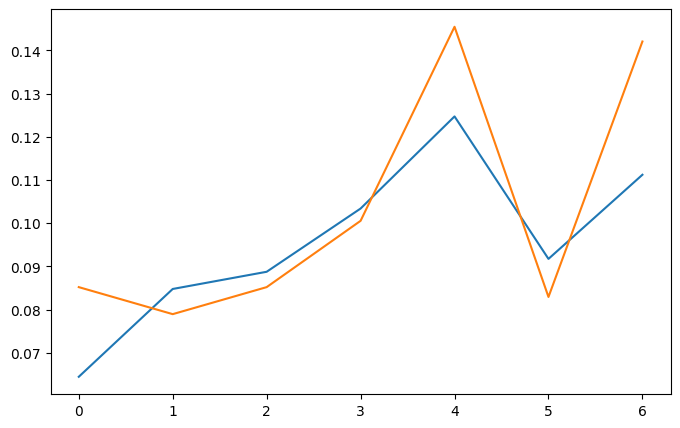

In [107]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

/tmp/ipykernel_1164/3510748923.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


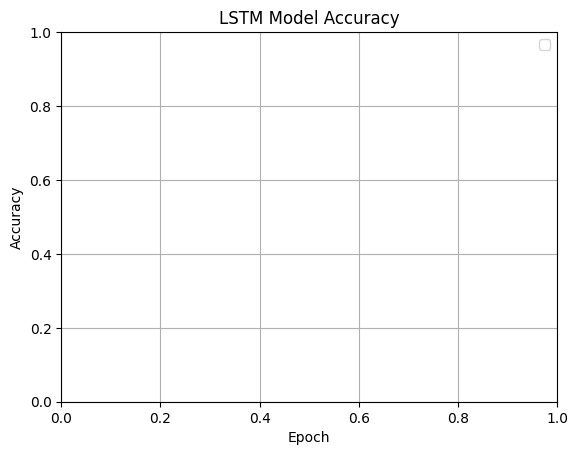

In [108]:
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [109]:
def predict_language(text):
    cleaned = clean_text(text)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

In [110]:
def predict_language(text):
    # Clean and prepare the input text
    cleaned = clean_text(text)
    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    # Predict class probabilities
    probabilities = model.predict(padded, verbose=0)[0]
    language_id = int(np.argmax(probabilities))

    # Decode the predicted class
    predicted_language = encoder.inverse_transform([language_id])[0]
    confidence = float(probabilities[language_id]) * 100

    return predicted_language, confidence

# Test the prediction function
test_text = "Bonjour tout le monde!"
pred_lang, conf = predict_language(test_text)
print(f"Text: '{test_text}'")
print(f"Predicted Language: {pred_lang} ({conf:.2f}% confidence)")

Text: 'Bonjour tout le monde!'
Predicted Language: Chinese (23.01% confidence)


In [111]:
# Set default test variables for the print statements
text = test_text
predicted_language = pred_lang
confidence = conf

print("\nInput text:", text)
print("Predicted language:", predicted_language)
print(f"Model confidence: {confidence:.2f}%")


Input text: Bonjour tout le monde!
Predicted language: Chinese
Model confidence: 23.01%


In [112]:
predict_language("Hello, how are you?")
predict_language("Bonjour tout le monde")
predict_language("Hola, buenos dias")


('Chinese', 23.009686172008514)

In [113]:
model.save("/content/language_lstm_model.keras")


In [114]:
print("\nModel saved successfully!")
print("File: /content/language_lstm_model.keras")


Model saved successfully!
File: /content/language_lstm_model.keras
